## Instructions
This file contains a comparison between the best model from each of the 3 missing-data handling approaches.

- Included NaN: XG Boost
- Imputed NaN: Custom Ensemble (KRR, XGB, Random Forest; equal weights). This was created in four blocks of code, as the three models had to be trained individually, then combined into the ensemble
- Dropped NaN: XG Boost

The first few code blocks contain the necessary code to run the models, as well as pre-processing steps. These include importing the necessary packages, reading the CSV file, splitting the data, defining the features and target variable, and defining the regression metrics function.

Two training sets were created to evaluate different strategies for handling missing data:

- **Training Set 1 – NaNs Dropped:** All rows containing missing values were removed, resulting in a complete dataset for models that cannot handle NaNs.

- **Training Set 2 – NaNs Retained:** All missing values were preserved in the dataset. This allowed models capable of handling NaNs to be trained on the original data. Models using median imputation also used this dataset, with missing values replaced by the median through the preprocessing pipeline.


A **shared test set** was created by removing all rows containing NaN values. This ensured that all models were evaluated on the same complete dataset, allowing for a fair comparison of predictive performance.





In [ ]:
# 0. Programming Environment Setup

# Numerical computing and data handling
import numpy as np
import pandas as pd
from pathlib import Path

#modelling`
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.metrics import r2_score
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.metrics import max_error, mean_absolute_error, mean_absolute_percentage_error, mean_squared_error
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import Ridge
from sklearn.kernel_ridge import KernelRidge
from sklearn.linear_model import Lasso
from math import degrees
from sklearn.preprocessing import PolynomialFeatures
from sklearn.ensemble import VotingRegressor
from sklearn.ensemble import RandomForestRegressor

from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from xgboost import XGBRegressor
from sklearn.neighbors import KNeighborsRegressor


#dummy modelling
from sklearn.dummy import DummyRegressor
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    max_error,
    mean_absolute_percentage_error,
    root_mean_squared_error
)


# plotting
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
%matplotlib inline


In [55]:
# 1.1 Pre-processing Part 1
# Import dataset, set random seed
DATA_DIR = Path.cwd().parent / "EDA"
INPUT_FILE = DATA_DIR / "cleaned_data.csv"

eda_df = pd.read_csv(INPUT_FILE, keep_default_na=False, na_values=[""])
includeNaN_df = eda_df.copy()
includeNaN_df = includeNaN_df.drop(columns=['Z', 'N'])
includeNaN_df.head() #Keep NaN
RANDOM_SEED = 1
np.random.seed(RANDOM_SEED)

In [56]:
# 1.2 Pre-processing Part 2
#split datset into test and train
df_train_includeNaN, df_test = train_test_split(
    includeNaN_df,
    test_size=0.2,  # 20% for testing
    random_state=RANDOM_SEED  # Ensure reproducibility
)
target_includeNaN = df_train_includeNaN['log_half_life'].name

features = [
    "A",
    "N/Z",
    "Q_beta_keV",
    "Q_alpha_keV",
    "S_n_keV",
    "S_p_keV"
]

#create training sets for dropped NaNs
df_train_dropNaN = df_train_includeNaN.dropna()
target_dropNaN = df_train_dropNaN['log_half_life'].name

#imputed NaNs
# don't have to create a separate training set since these will be imputed from includeNaN_df using Pipelines


#TEST SET
df_test = df_test.dropna() #complete test set, drops all NaNs, we will use this test set for all models

print(df_train_dropNaN.shape)


(1306, 8)


In [57]:
#Regression metrics function
def get_regression_metrics(model, X, y_true):

    y_predicted = model.predict(X)

    mae = mean_absolute_error(y_true, y_predicted)
    mse = mean_squared_error(y_true, y_predicted)
    maximum_error = max_error(y_true, y_predicted)
    rmse = root_mean_squared_error(y_true, y_predicted)

    metrics_dict = {
        'mae': mae,
        'mse': mse,
        'max_error': maximum_error,
        'rmse': rmse,
        'r^2': r2_score(y_true, y_predicted)
    }

    return metrics_dict

In [58]:
# 2. Include NaN Best Model: XG Boost
xgb_includeNaN = Pipeline([
    ('scaling', StandardScaler()),
    ('xgb', XGBRegressor(
        n_estimators=1200,
        learning_rate=0.1,
        max_depth=7,
        random_state=RANDOM_SEED
    ))
])

xgb_includeNaN.fit(df_train_includeNaN[features], df_train_includeNaN[target_includeNaN])

xgb_includeNaN_results_train = get_regression_metrics(
    xgb_includeNaN, df_train_includeNaN[features], df_train_includeNaN[target_includeNaN]
)

xgb_includeNaN_results_test = get_regression_metrics(
    xgb_includeNaN, df_test[features], df_test[target_includeNaN]
)

# Create dataframe
xgb_includeNaN_results_df = pd.DataFrame(
    [xgb_includeNaN_results_train, xgb_includeNaN_results_test],
    index=['Train', 'Test']
)

# Round to 4 decimal places
xgb_includeNaN_results_df = xgb_includeNaN_results_df.round(4)

# Add model name
xgb_includeNaN_results_df.insert(0, 'Model', 'XGboost Regression')

# Display dataframe
display(xgb_includeNaN_results_df)

,Model,mae,mse,max_error,rmse,r^2
Train,XGboost Regression,0.0038,0.0002,0.3745,0.0130,1.0000
Test,XGboost Regression,0.8082,1.5151,5.9743,1.2309,0.8547


In [59]:
# 3.1 Imputed Model Best Model: Custom Ensemble Part 1 (XGBoost)
 
xgb_imputeNaN = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaling', StandardScaler()),
    ('xgb', XGBRegressor(
        n_estimators=300,
        learning_rate=0.1,
        max_depth=5,
        random_state=RANDOM_SEED
    ))
])

xgb_imputeNaN.fit(df_train_includeNaN[features], df_train_includeNaN[target_includeNaN])

xgb_imputeNaN_results_train = get_regression_metrics(
    xgb_imputeNaN, df_train_includeNaN[features], df_train_includeNaN[target_includeNaN]
)

xgb_imputeNaN_results_test = get_regression_metrics(
    xgb_imputeNaN, df_test[features], df_test[target_includeNaN]
)

# Create dataframe
xgb_imputeNaN_results_df = pd.DataFrame(
    [xgb_imputeNaN_results_train, xgb_imputeNaN_results_test],
    index=['Train', 'Test']
)

# Round to 4 decimal places
xgb_imputeNaN_results_df = xgb_imputeNaN_results_df.round(4)

# Add model name
xgb_imputeNaN_results_df.insert(0, 'Model', 'XGBoost Regression')

# Display dataframe
display(xgb_imputeNaN_results_df)


,Model,mae,mse,max_error,rmse,r^2
Train,XGBoost Regression,0.3346,0.2305,3.3457,0.4801,0.9777
Test,XGBoost Regression,0.8401,1.5731,5.3871,1.2542,0.8491


In [60]:
#3.2 Imputed Model Best Model: Custom Ensemble Part 2 (Random Forest)
rf_imputeNaN = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaling', StandardScaler()),
    ('rf', RandomForestRegressor(
        n_estimators=300,
        max_depth=20,
        min_samples_split=2,
        min_samples_leaf=1,
        random_state=RANDOM_SEED
    ))
])

rf_imputeNaN.fit(df_train_includeNaN[features], df_train_includeNaN[target_includeNaN])

rf_imputeNaN_results_train = get_regression_metrics(
    rf_imputeNaN, df_train_includeNaN[features], df_train_includeNaN[target_includeNaN]
)

rf_imputeNaN_results_test = get_regression_metrics(
    rf_imputeNaN, df_test[features], df_test[target_includeNaN]
)

# Create dataframe
rf_imputeNaN_results_df = pd.DataFrame(
    [rf_imputeNaN_results_train, rf_imputeNaN_results_test],
    index=['Train', 'Test']
)

# Round to 4 decimal places
rf_imputeNaN_results_df = rf_imputeNaN_results_df.round(4)

# Add model name
rf_imputeNaN_results_df.insert(0, 'Model', 'Random Forest')

# Display dataframe
display(rf_imputeNaN_results_df)


,Model,mae,mse,max_error,rmse,r^2
Train,Random Forest,0.3460,0.3018,6.0706,0.5494,0.9708
Test,Random Forest,0.8333,1.7012,7.6500,1.3043,0.8368


In [61]:
# 3.3 Imputed Model Best Model: Custom Ensemble Part 3 (KNN)
krr_imputeNaN = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaling', StandardScaler()),
    ('krr', KernelRidge(
        alpha=0.1,
        kernel='rbf',
        gamma=1.0
    ))
])


krr_imputeNaN.fit(df_train_includeNaN[features], df_train_includeNaN[target_includeNaN])

krr_imputeNaN_results_train = get_regression_metrics(
    krr_imputeNaN, df_train_includeNaN[features], df_train_includeNaN[target_includeNaN]
)

krr_imputeNaN_results_test = get_regression_metrics(
    krr_imputeNaN, df_test[features], df_test[target_includeNaN]
)

# Create dataframe
krr_imputeNaN_results_df = pd.DataFrame(
    [krr_imputeNaN_results_train, krr_imputeNaN_results_test],
    index=['Train', 'Test']
)

# Round to 4 decimal places
krr_imputeNaN_results_df = krr_imputeNaN_results_df.round(4)

# Add model name
krr_imputeNaN_results_df.insert(0, 'Model', 'Kernel Ridge Regression')

# Display dataframe
display(krr_imputeNaN_results_df)

,Model,mae,mse,max_error,rmse,r^2
Train,Kernel Ridge Regression,0.6708,1.0812,8.2907,1.0398,0.8953
Test,Kernel Ridge Regression,0.8741,1.8428,6.2635,1.3575,0.8232


In [62]:
#3.4 Imputed Model Best Model: Custom Ensemble Part 4
#created custom ensemble model using previous 3 models

ensemble_model = VotingRegressor(
    estimators=[
        ('random forest', rf_imputeNaN),
        ('xgb', xgb_imputeNaN),
        ('krr', krr_imputeNaN),
    ]
)

ensemble_model.fit(
    df_train_includeNaN[features],
    df_train_includeNaN[target_includeNaN]
)
ensemble_model_results_train = get_regression_metrics(ensemble_model, df_train_includeNaN[features], df_train_includeNaN[target_includeNaN])
ensemble_model_results_test = get_regression_metrics(ensemble_model, df_test[features], df_test[target_includeNaN])

# Create dataframe
ensemble_model_results_df = pd.DataFrame(
    [ensemble_model_results_train, ensemble_model_results_test],
    index=['Train', 'Test']
)

# Round to 4 decimal places
ensemble_model_results_df = ensemble_model_results_df.round(4)

# Add model name
ensemble_model_results_df.insert(0, 'Model', 'Ensemble')

# Display dataframe
display(ensemble_model_results_df)

,Model,mae,mse,max_error,rmse,r^2
Train,Ensemble,0.4120,0.3915,3.6369,0.6257,0.9621
Test,Ensemble,0.7878,1.4890,5.4733,1.2203,0.8572


In [63]:
# 4. Dropped NaN Best Model: XG Boost
xgb_dropNaN = Pipeline([
    ('scaling', StandardScaler()),
    ('xgb', XGBRegressor(
        n_estimators=300,
        learning_rate=0.1,
        max_depth=5,
        random_state=RANDOM_SEED
    ))
])


xgb_dropNaN.fit(df_train_dropNaN[features], df_train_dropNaN[target_dropNaN])

xgb_dropNaN_results_train = get_regression_metrics(
    xgb_dropNaN, df_train_dropNaN[features], df_train_dropNaN[target_dropNaN]
)

xgb_dropNaN_results_test = get_regression_metrics(
    xgb_dropNaN, df_test[features], df_test[target_dropNaN]
)

# Create dataframe
xgb_dropNaN_results_df = pd.DataFrame(
    [xgb_dropNaN_results_train, xgb_dropNaN_results_test],
    index=['Train', 'Test']
)

# Round to 4 decimal places
xgb_dropNaN_results_df = xgb_dropNaN_results_df.round(4)

# Add model name
xgb_dropNaN_results_df.insert(0, 'Model', 'XG Boost (Dropped)')

# Display dataframe
display(xgb_dropNaN_results_df)

,Model,mae,mse,max_error,rmse,r^2
Train,XG Boost (Dropped),0.2173,0.0923,1.4582,0.3038,0.9913
Test,XG Boost (Dropped),0.7877,1.3964,5.1588,1.1817,0.8661


In [64]:
# 5. Create dataframe containing all test results
all_results_test_df = pd.DataFrame({
    'Drop NaN (XGB)': xgb_dropNaN_results_test,
    'Include NaN (XBoost)': xgb_includeNaN_results_test,
    'Impute NaN (Custom Ensemble)': ensemble_model_results_test,

})

# Transpose dataframe
all_results_test_df = all_results_test_df.T

# Add model categories
all_results_test_df.insert(0, 'Model Category', [
    'Ensemble',
    'Ensemble',
    'Ensemble'])

# Add model names
all_results_test_df.insert(1, 'Model', all_results_test_df.index)

# Reset index
all_results_test_df = all_results_test_df.reset_index(drop=True)

# Round to 4 decimal places
all_results_test_df = all_results_test_df.round(4)


# Display test results
print("\nTEST SET MODEL PERFORMANCE")
display(all_results_test_df)


TEST SET MODEL PERFORMANCE


,Model Category,Model,mae,mse,max_error,rmse,r^2
0,Ensemble,Drop NaN (XGB),0.7877,1.3964,5.1588,1.1817,0.8661
1,Ensemble,Include NaN (XBoost),0.8082,1.5151,5.9743,1.2309,0.8547
2,Ensemble,Impute NaN (Custom Ensemble),0.7878,1.4890,5.4733,1.2203,0.8572


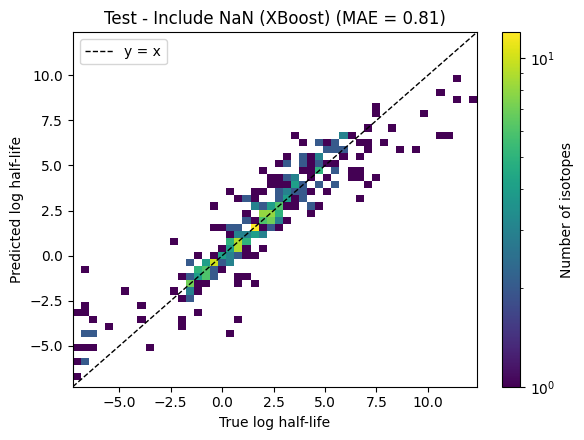

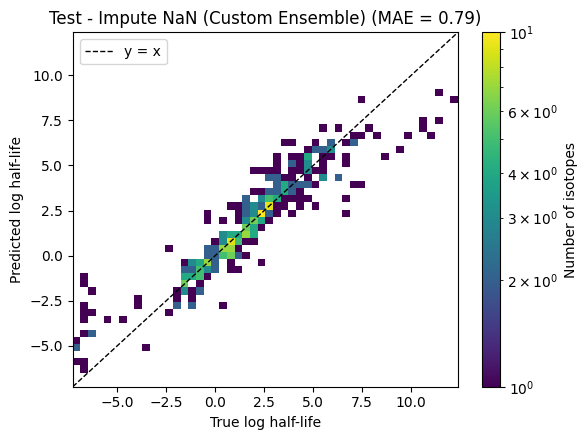

In [65]:
# 6.1 Parity plots for included NaN and imputed NaN models
models = {
    'Include NaN (XBoost)': xgb_includeNaN,
    'Impute NaN (Custom Ensemble)': ensemble_model,
}

# Define parity plot function
def hist_density(y_true, y_pred, xlabel='True log half-life',
                 ylabel='Predicted log half-life', title=None, bins=50):

    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)

    lims = [
        min(y_true.min(), y_pred.min()),
        max(y_true.max(), y_pred.max())
    ]

    mae = np.mean(np.abs(y_true - y_pred))

    # Create individual figure
    fig, ax = plt.subplots(figsize=(6, 4.5))

    h = ax.hist2d(
        y_true, y_pred,
        bins=bins,
        range=[lims, lims],
        cmin=1,
        cmap='viridis',
        norm=LogNorm()
    )

    # Add colour bar
    fig.colorbar(h[3], ax=ax, label='Number of isotopes')

    # Add parity line
    ax.plot(lims, lims, 'k--', lw=1, label='y = x')

    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_title(
        f"{title} (MAE = {mae:.2f})" if title else f"MAE = {mae:.2f}"
    )

    ax.legend(loc='upper left')

    plt.tight_layout()
    plt.show()


# Generate individual parity plots for all models
for name, model in models.items():

    y_pred = model.predict(df_test[features])

    hist_density(
        df_test[target_includeNaN],
        y_pred,
        title=f'Test - {name}'
    )

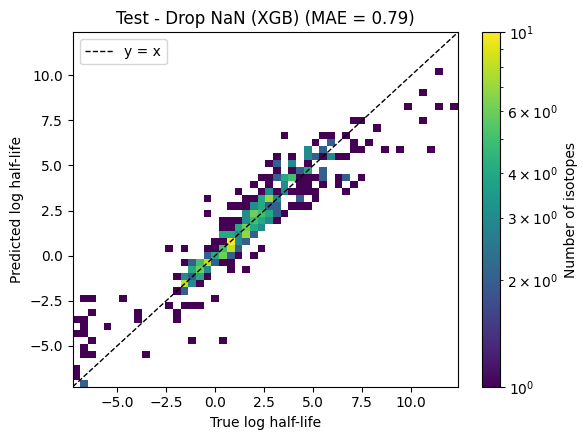

In [66]:
# 6.2 Parity plots for dropped NaN model
models = {
    'Drop NaN (XGB)': xgb_dropNaN
}

# Define parity plot function
def hist_density(y_true, y_pred, xlabel='True log half-life',
                 ylabel='Predicted log half-life', title=None, bins=50):

    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)

    lims = [
        min(y_true.min(), y_pred.min()),
        max(y_true.max(), y_pred.max())
    ]

    mae = np.mean(np.abs(y_true - y_pred))

    # Create individual figure
    fig, ax = plt.subplots(figsize=(6, 4.5))

    h = ax.hist2d(
        y_true, y_pred,
        bins=bins,
        range=[lims, lims],
        cmin=1,
        cmap='viridis',
        norm=LogNorm()
    )

    # Add colour bar
    fig.colorbar(h[3], ax=ax, label='Number of isotopes')

    # Add parity line
    ax.plot(lims, lims, 'k--', lw=1, label='y = x')

    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_title(
        f"{title} (MAE = {mae:.2f})" if title else f"MAE = {mae:.2f}"
    )

    ax.legend(loc='upper left')

    plt.tight_layout()
    plt.show()


# Generate individual parity plots for all models
for name, model in models.items():

    y_pred = model.predict(df_test[features])

    hist_density(
        df_test[target_dropNaN],
        y_pred,
        title=f'Test - {name}'
    )